[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/keyvanmahmoudi/Data_Science_Course/blob/main/notebooks/05_data_visualization.ipynb)

<div dir="rtl">

# جلسه ۵: رسم نمودار با Matplotlib و Seaborn

**اهداف این جلسه**

- ساختار یک نمودار در Matplotlib: `Figure` و `Axes`
- نمودارهای پایه: خطی، میله‌ای، هیستوگرام، پراکندگی و جعبه‌ای
- چند نمودار کنار هم با `subplots`
- رسم آماری سریع با Seaborn و رنگ‌بندی بر اساس متغیر دسته‌ای (`hue`)
- **انتخاب نمودار درست** برای هر سؤال
- اصول نمودار صادق و خوانا، و نمودارهای گمراه‌کننده
- ذخیره‌ی نمودار با کیفیت مناسب برای گزارش و مقاله

نمودار خوب، یک **جمله** را به خواننده منتقل می‌کند. قبل از رسم هر نمودار از خودتان بپرسید: این نمودار قرار است چه جمله‌ای بگوید؟

</div>

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

DATA_URL = "https://raw.githubusercontent.com/keyvanmahmoudi/Data_Science_Course/main/data/"

penguins = pd.read_csv(DATA_URL + "penguins.csv").dropna()
tips = pd.read_csv(DATA_URL + "tips.csv")
orders = pd.read_csv(DATA_URL + "orders_clean.csv", parse_dates=["order_date"])
print(penguins.shape, tips.shape, orders.shape)

(333, 7) (244, 7) (1196, 10)


<div dir="rtl">

## ۱. آناتومی یک نمودار در Matplotlib

- **Figure**: کل بوم (پنجره یا تصویر نهایی)
- **Axes**: یک نمودار مشخص داخل بوم، با محورها، عنوان و داده
- یک Figure می‌تواند چند Axes داشته باشد.

روش توصیه‌شده، ساختن صریح هر دو با `plt.subplots()` و رسم روی `ax` است (سبک شیءگرا). این روش در نمودارهای چندتایی بسیار خواناتر از دستورهای `plt.plot` پشت سر هم است.

</div>

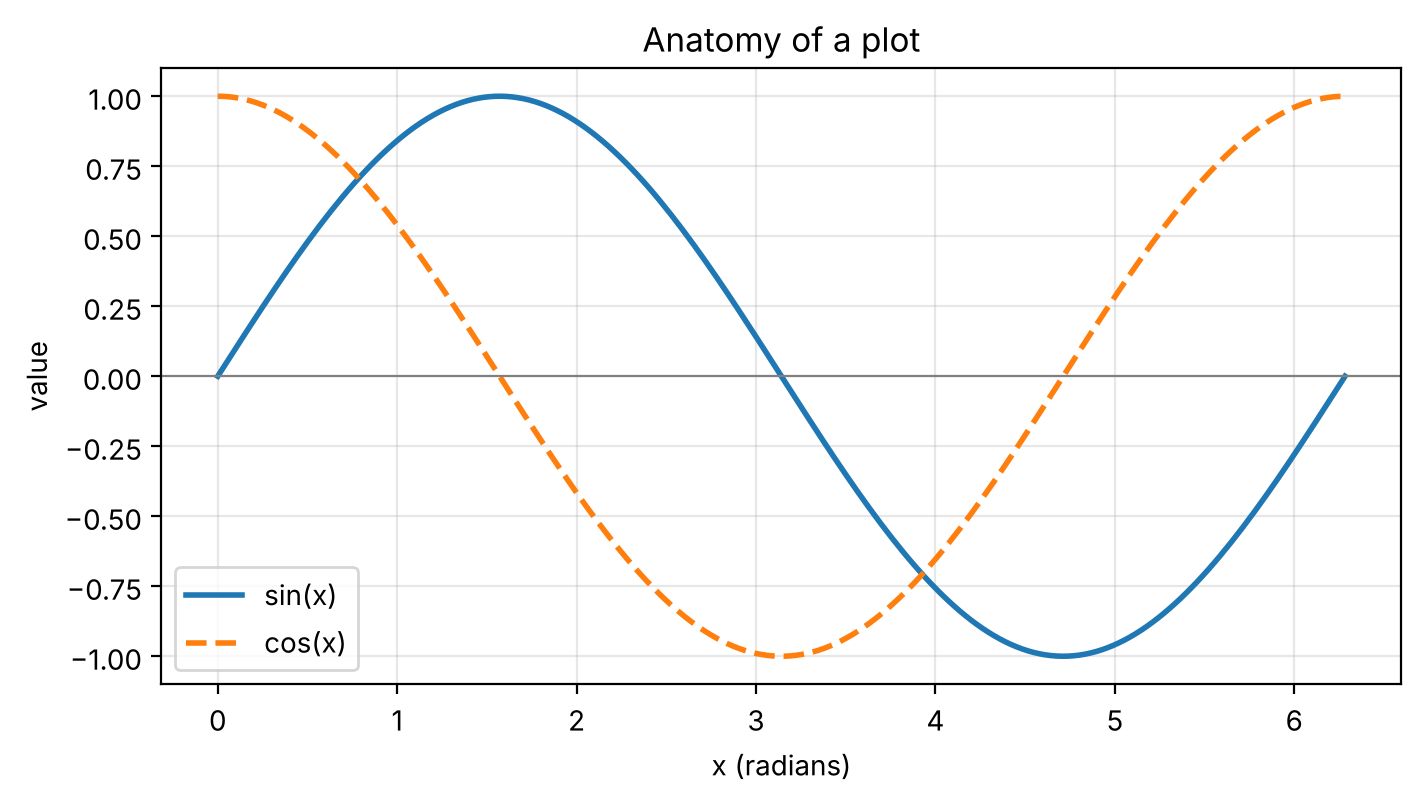

In [2]:
x = np.linspace(0, 2 * np.pi, 200)

fig, ax = plt.subplots(figsize=(8, 4))
ax.plot(x, np.sin(x), label="sin(x)", linewidth=2)
ax.plot(x, np.cos(x), label="cos(x)", linewidth=2, linestyle="--")
ax.set_title("Anatomy of a plot")
ax.set_xlabel("x (radians)")
ax.set_ylabel("value")
ax.axhline(0, color="gray", linewidth=0.8)
ax.legend()
ax.grid(alpha=0.3)
plt.show()

<div dir="rtl">

## ۲. پنج نمودار پایه

| سؤال | نمودار |
|---|---|
| تغییر یک مقدار در **زمان** | خطی (`plot`) |
| مقایسه‌ی مقدار بین **دسته‌ها** | میله‌ای (`bar` / `barh`) |
| **توزیع** یک متغیر عددی | هیستوگرام (`hist`) |
| **رابطه**‌ی دو متغیر عددی | پراکندگی (`scatter`) |
| مقایسه‌ی **توزیع** بین دسته‌ها | جعبه‌ای (`boxplot`) |

</div>

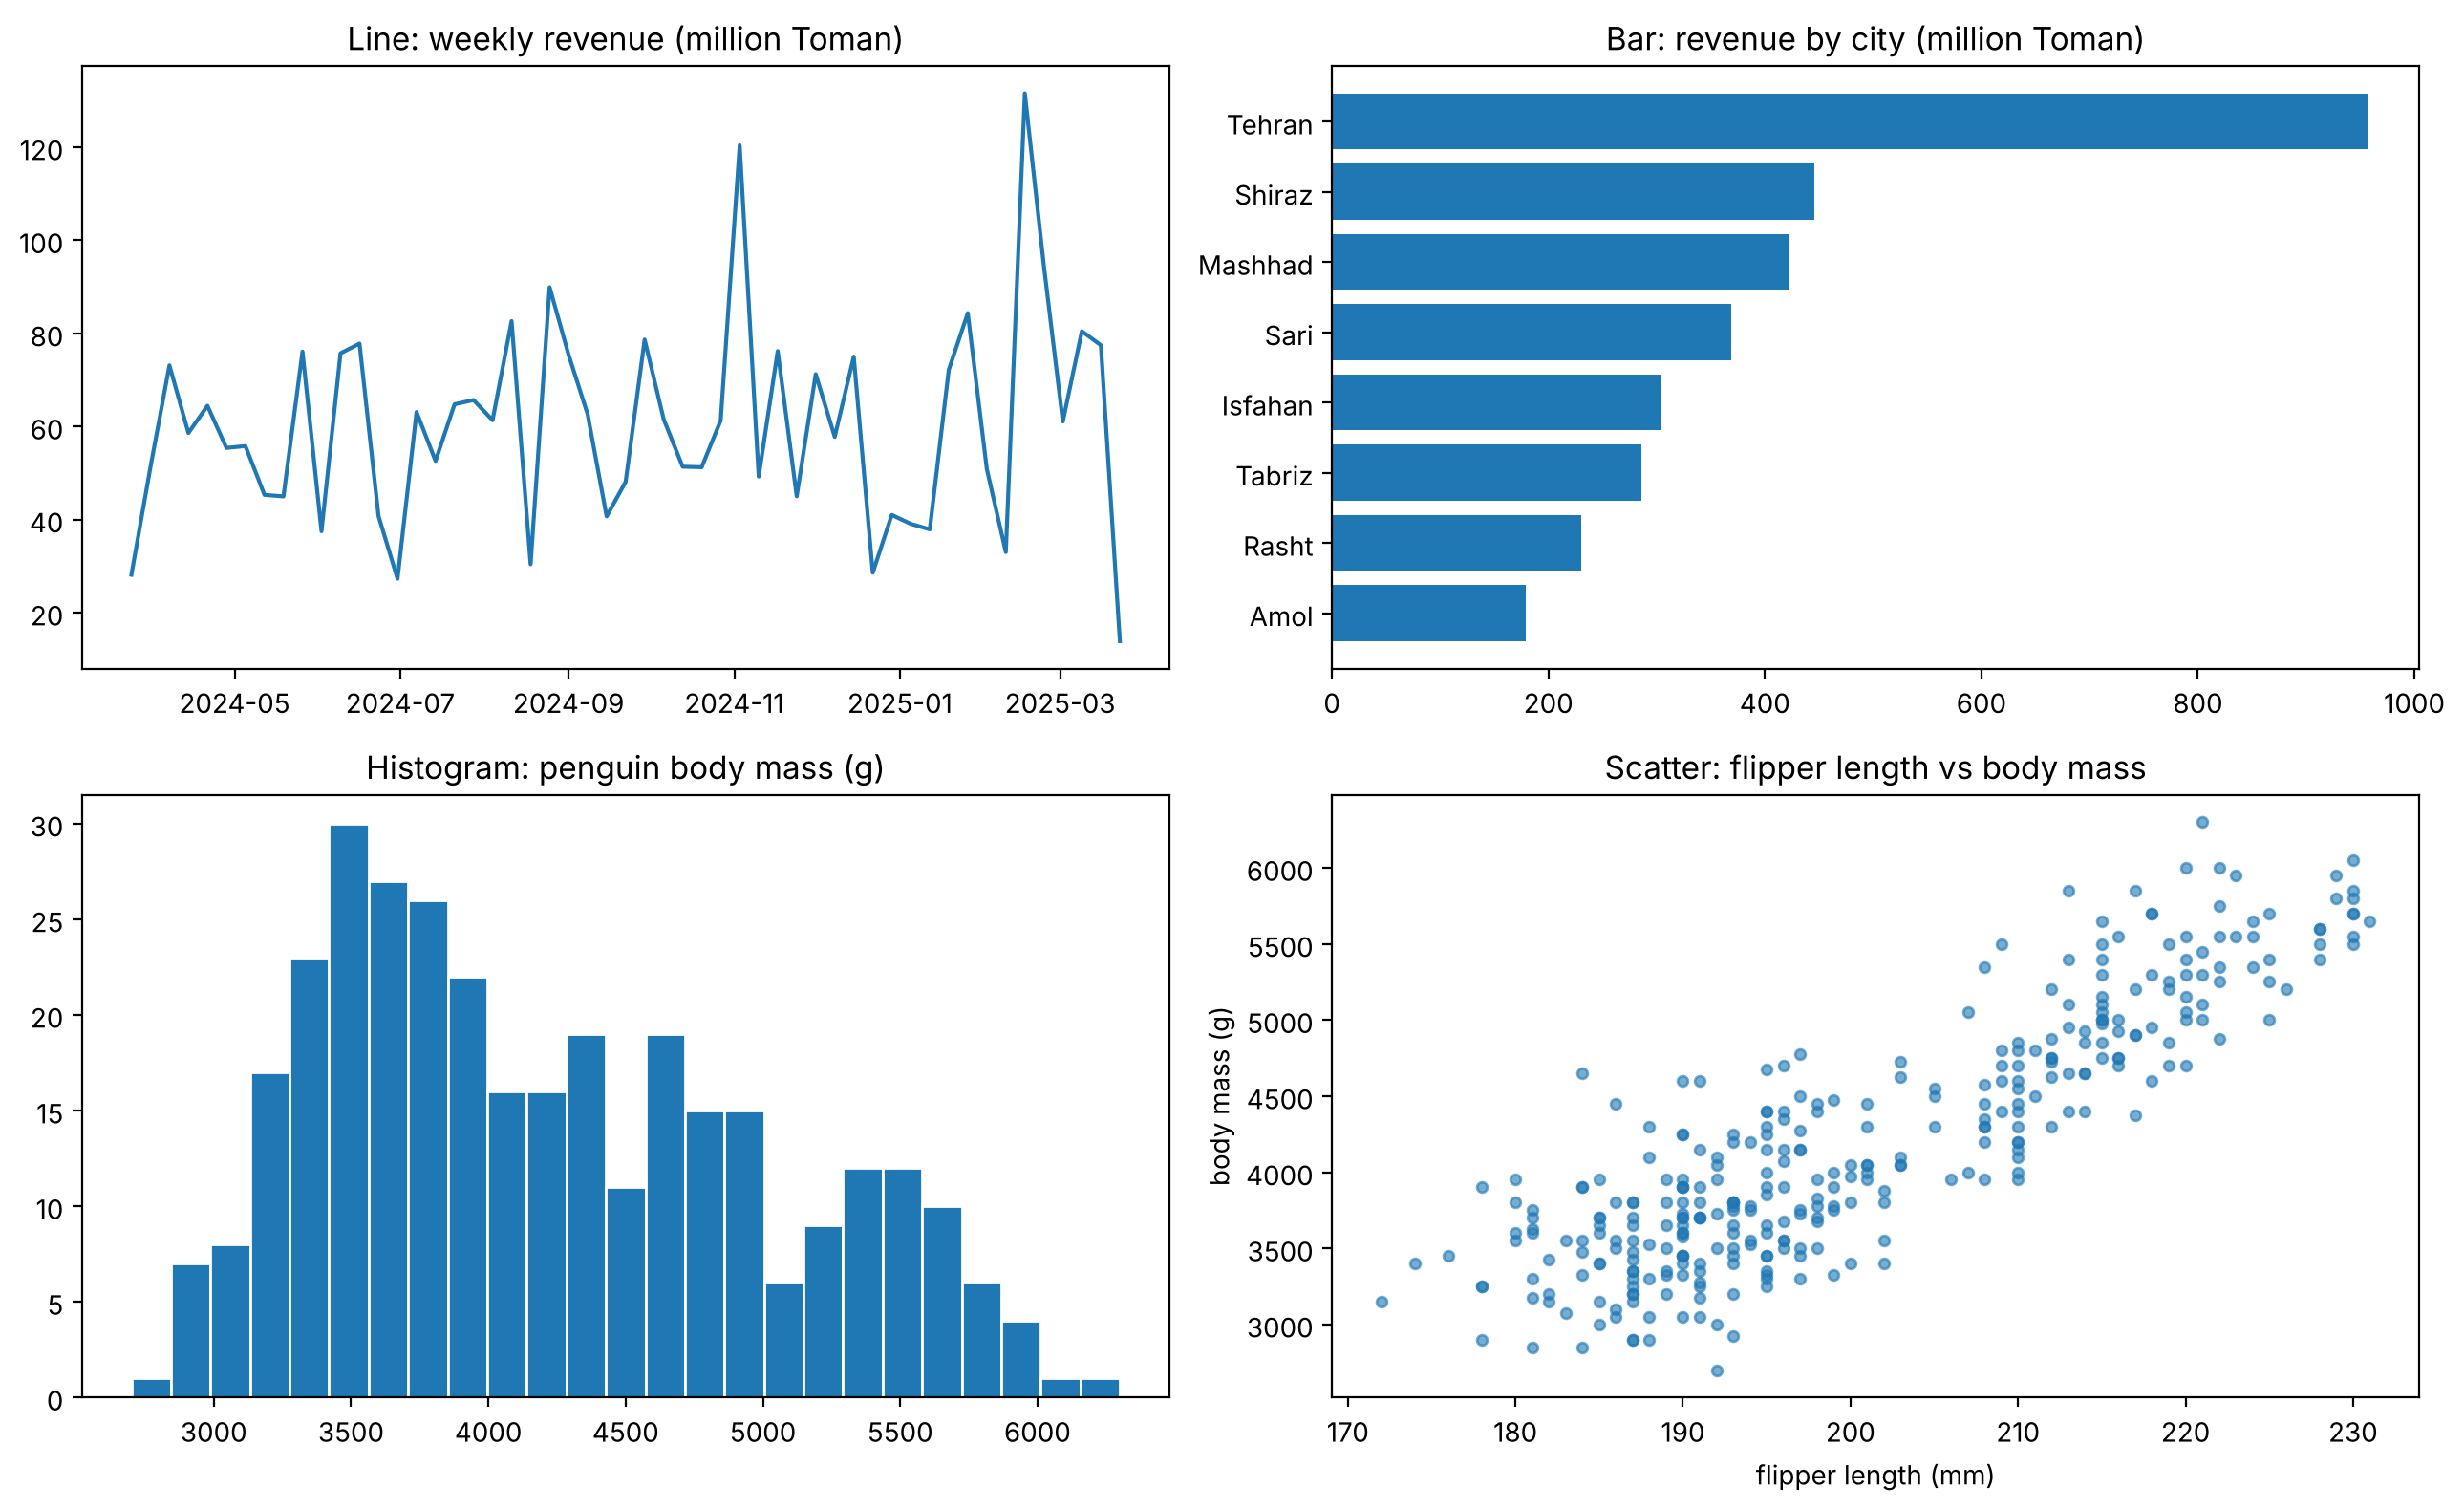

In [3]:
daily = orders.set_index("order_date").resample("W")["total_price"].sum() / 1e6
city_rev = orders.groupby("city")["total_price"].sum().sort_values() / 1e6

fig, axes = plt.subplots(2, 2, figsize=(13, 8))

axes[0, 0].plot(daily.index, daily.values, color="tab:blue")
axes[0, 0].set_title("Line: weekly revenue (million Toman)")

axes[0, 1].barh(city_rev.index, city_rev.values, color="tab:blue")
axes[0, 1].set_title("Bar: revenue by city (million Toman)")

axes[1, 0].hist(penguins["body_mass_g"], bins=25, color="tab:blue", edgecolor="white")
axes[1, 0].set_title("Histogram: penguin body mass (g)")

axes[1, 1].scatter(penguins["flipper_length_mm"], penguins["body_mass_g"], s=15, alpha=0.6)
axes[1, 1].set_title("Scatter: flipper length vs body mass")
axes[1, 1].set_xlabel("flipper length (mm)")
axes[1, 1].set_ylabel("body mass (g)")

plt.tight_layout()
plt.show()

<div dir="rtl">

چند نکته درباره‌ی انتخاب‌های بالا:

- میله‌ها **افقی** و **مرتب‌شده** هستند. با نام‌های طولانی، میله‌ی افقی خواناتر است و مرتب‌سازی مقایسه را آسان می‌کند.
- همه‌ی میله‌ها یک رنگ دارند؛ رنگ متفاوت برای هر شهر اطلاع جدیدی اضافه نمی‌کرد.
- در نمودار پراکندگی از `alpha` (شفافیت) استفاده کردیم تا نقاط روی هم دیده شوند.

</div>

<div dir="rtl">

### هیستوگرام: تعداد دسته‌ها (bins) مهم است

تعداد bins می‌تواند شکل توزیع را پنهان یا آشکار کند. توزیع وزن پنگوئن‌ها را با سه انتخاب ببینید:

</div>

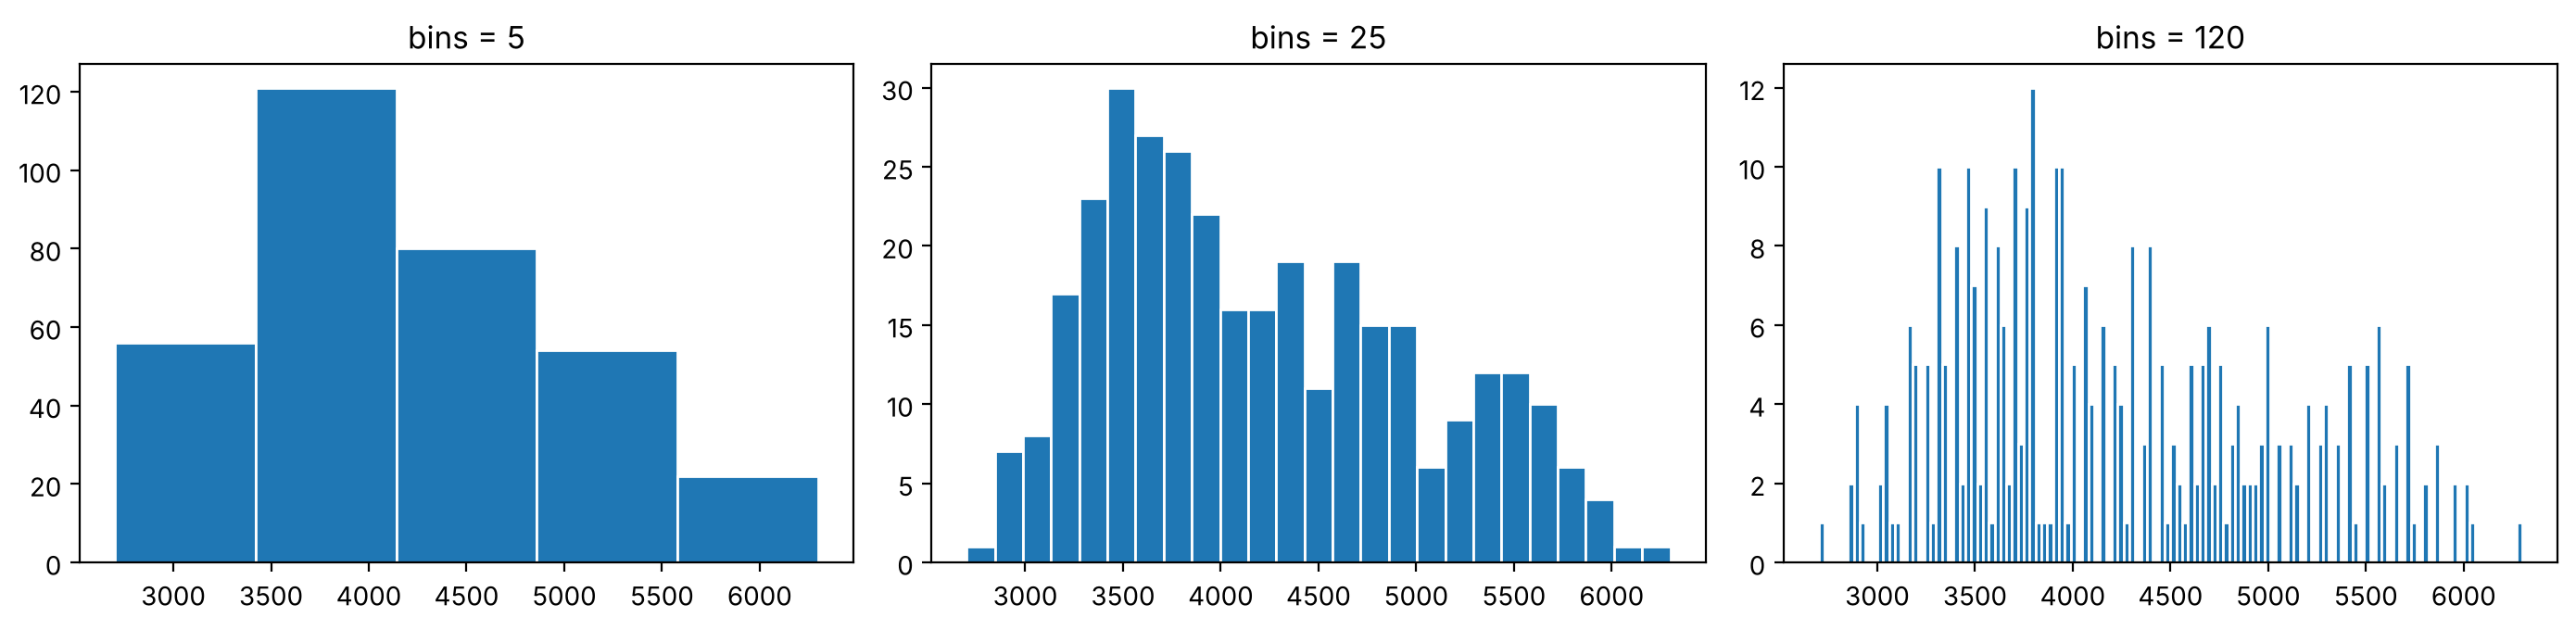

In [4]:
fig, axes = plt.subplots(1, 3, figsize=(14, 3.5), sharey=False)
for ax, bins in zip(axes, [5, 25, 120]):
    ax.hist(penguins["body_mass_g"], bins=bins, color="tab:blue", edgecolor="white")
    ax.set_title(f"bins = {bins}")
plt.tight_layout()
plt.show()

<div dir="rtl">

با ۵ دسته، توزیع یک‌قله‌ای به نظر می‌رسد؛ با ۲۵ دسته، دو قله پیدا می‌شود (که بعداً می‌فهمیم مربوط به گونه‌های مختلف است)؛ با ۱۲۰ دسته، نمودار پر از نویز است.

</div>

<div dir="rtl">

## ۳. Seaborn: نمودار آماری با کد کم

Seaborn روی Matplotlib ساخته شده و مستقیم با `DataFrame` کار می‌کند. بزرگ‌ترین مزیتش، پارامتر `hue` است که داده را بر اساس یک متغیر دسته‌ای رنگ‌بندی می‌کند.

</div>

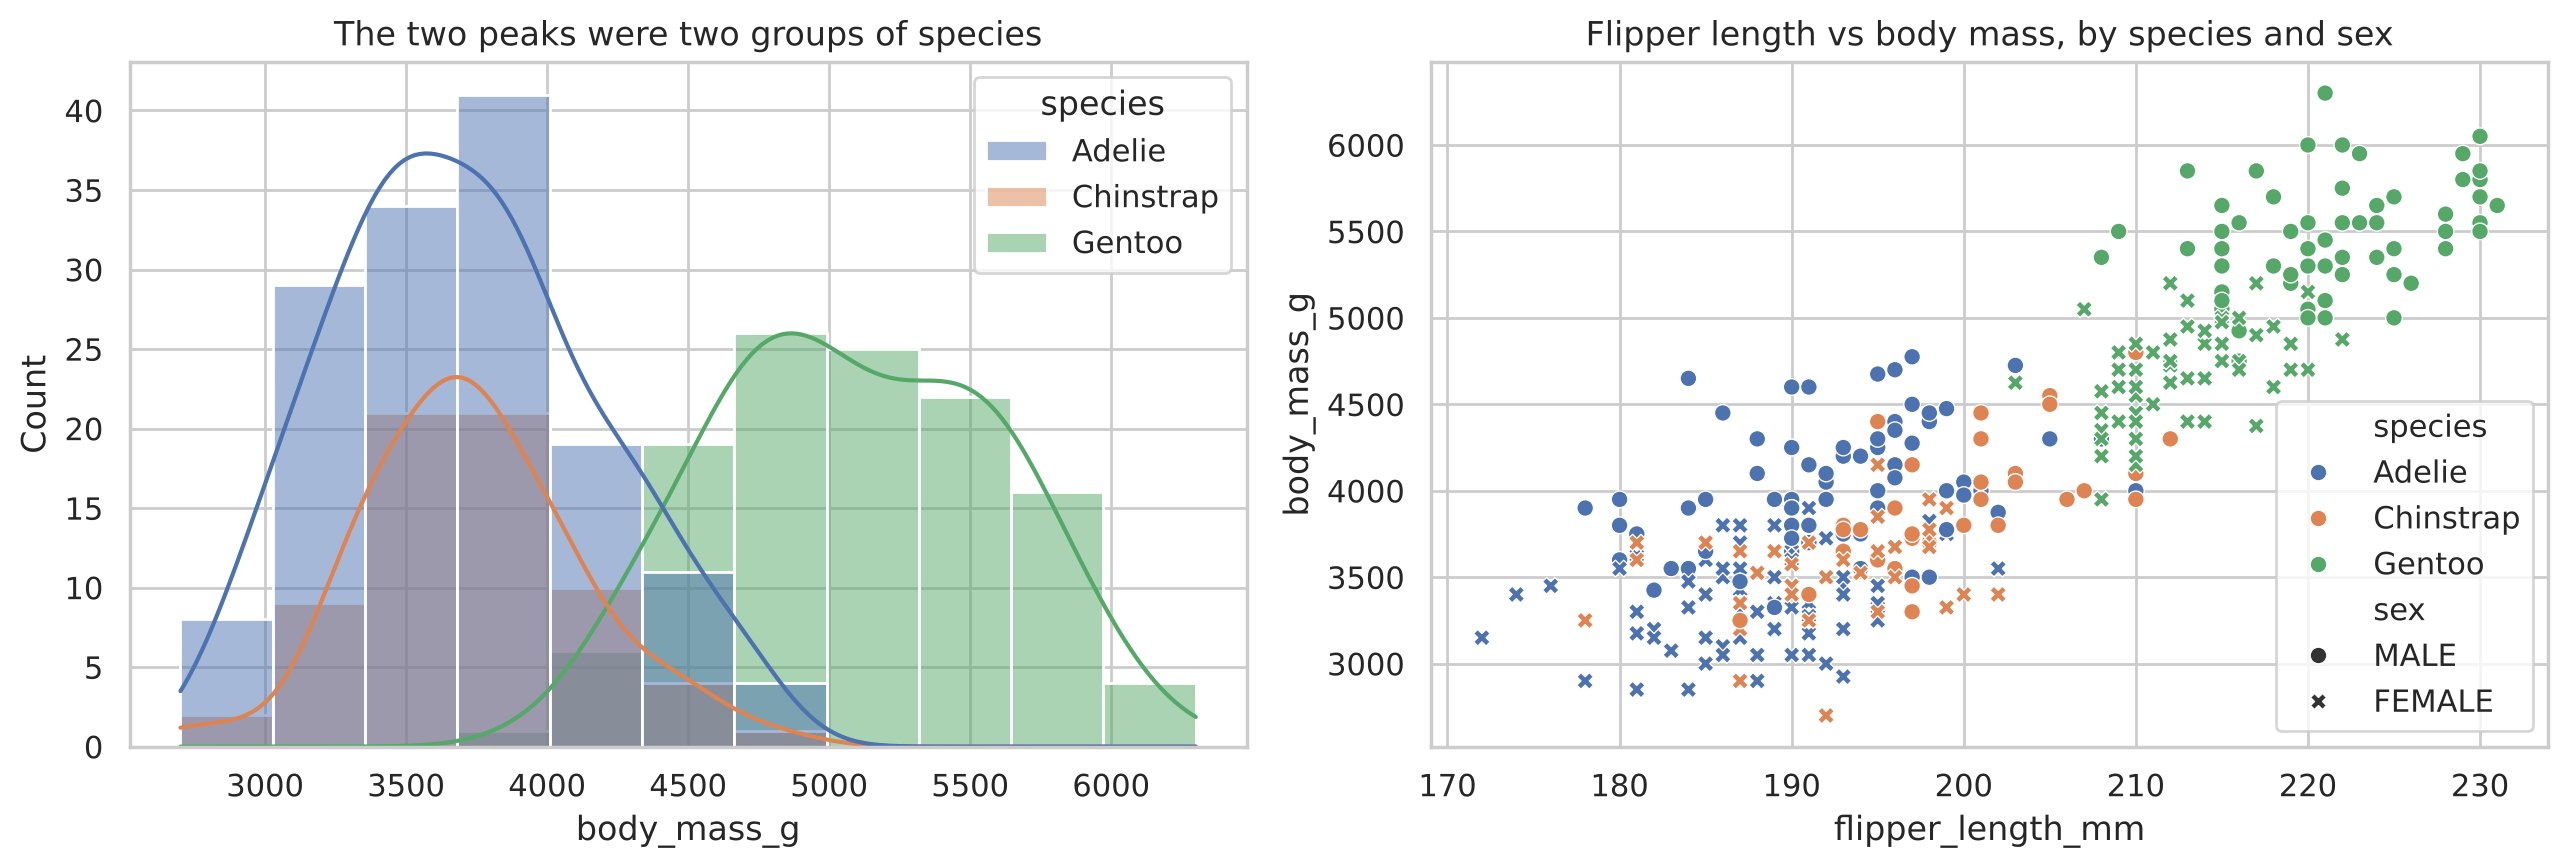

In [5]:
sns.set_theme(style="whitegrid")

fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
sns.histplot(data=penguins, x="body_mass_g", hue="species", kde=True, ax=axes[0])
axes[0].set_title("The two peaks were two groups of species")
sns.scatterplot(data=penguins, x="flipper_length_mm", y="body_mass_g",
                hue="species", style="sex", ax=axes[1])
axes[1].set_title("Flipper length vs body mass, by species and sex")
plt.tight_layout()
plt.show()

<div dir="rtl">

### مقایسه‌ی توزیع بین گروه‌ها

- **Box plot**: میانه، چارک‌ها و داده‌های پرت را خلاصه می‌کند.
- **Violin plot**: شکل کامل توزیع را هم نشان می‌دهد.
- **Strip plot**: تک‌تک نقاط را نشان می‌دهد؛ برای داده‌ی کم، صادقانه‌ترین انتخاب است.

</div>

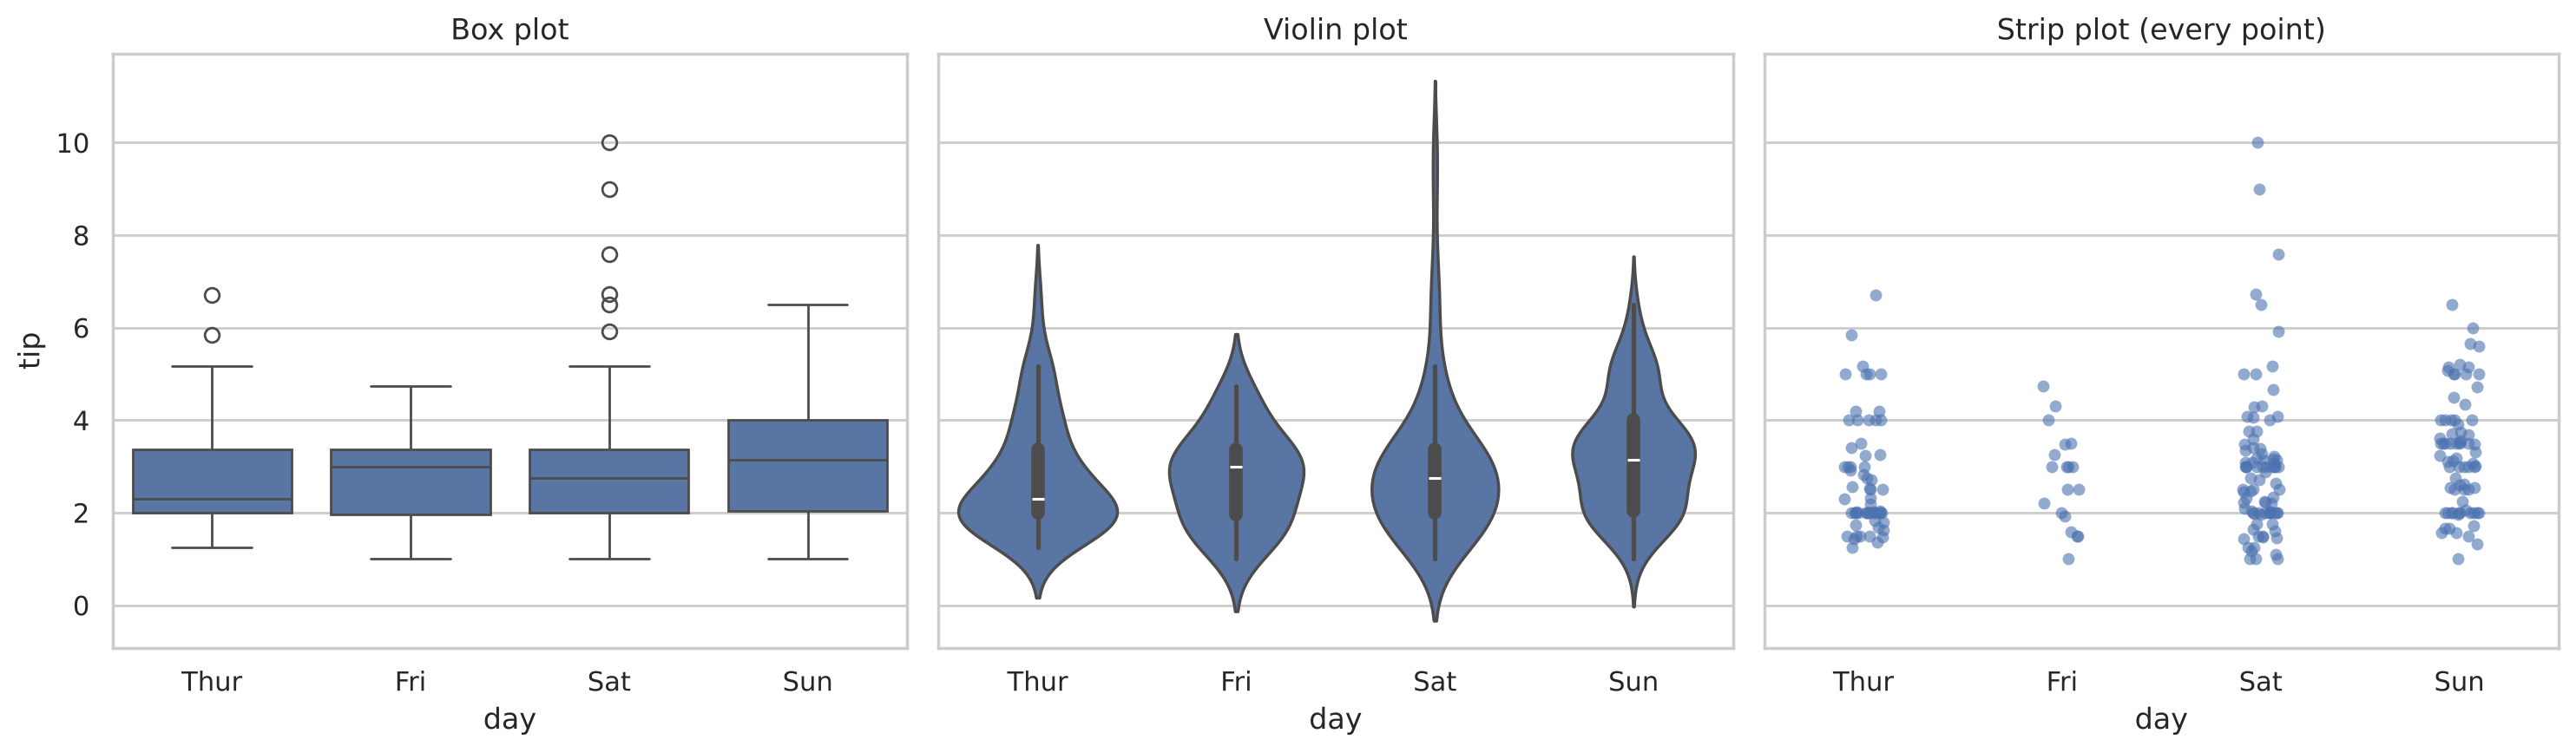

In [6]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4.5), sharey=True)
sns.boxplot(data=tips, x="day", y="tip", order=["Thur", "Fri", "Sat", "Sun"], ax=axes[0])
axes[0].set_title("Box plot")
sns.violinplot(data=tips, x="day", y="tip", order=["Thur", "Fri", "Sat", "Sun"], ax=axes[1])
axes[1].set_title("Violin plot")
sns.stripplot(data=tips, x="day", y="tip", order=["Thur", "Fri", "Sat", "Sun"], alpha=0.6, ax=axes[2])
axes[2].set_title("Strip plot (every point)")
plt.tight_layout()
plt.show()

In [7]:
print(tips["day"].value_counts())

day
Sat     87
Sun     76
Thur    62
Fri     19
Name: count, dtype: int64


<div dir="rtl">

نمودار نقطه‌ای چیزی را نشان می‌دهد که جعبه و ویولن پنهان کرده‌اند: روز جمعه فقط ۱۹ مشاهده داریم. نتیجه‌گیری درباره‌ی جمعه باید با احتیاط بیشتری باشد.

### میانگین گروه‌ها با بازه‌ی اطمینان

`barplot` در Seaborn به‌طور پیش‌فرض **میانگین** هر گروه را رسم می‌کند و یک خط خطا (بازه‌ی اطمینان ۹۵٪) هم اضافه می‌کند. معنای دقیق بازه‌ی اطمینان را در جلسه‌ی ۹ می‌بینیم.

</div>

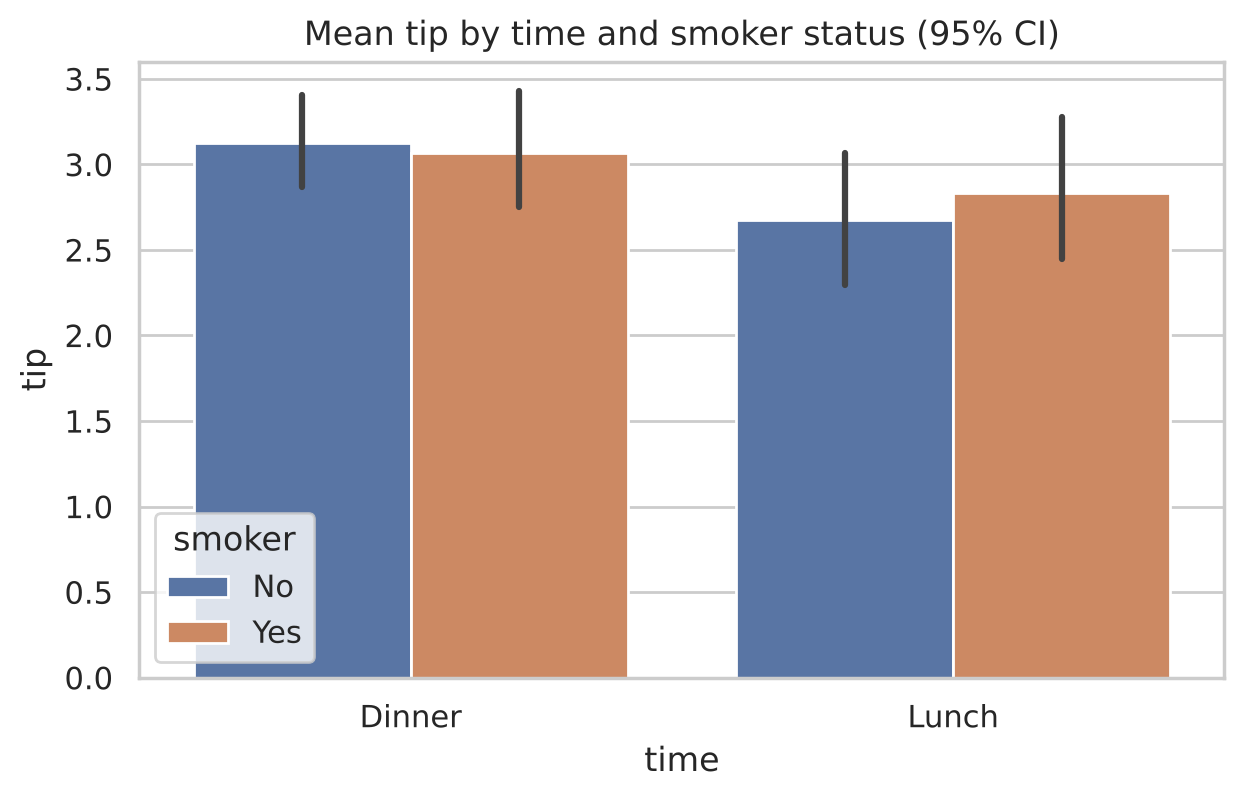

In [8]:
fig, ax = plt.subplots(figsize=(7, 4))
sns.barplot(data=tips, x="time", y="tip", hue="smoker", ax=ax)
ax.set_title("Mean tip by time and smoker status (95% CI)")
plt.show()

<div dir="rtl">

### رابطه‌ی همه‌ی متغیرها با هم: `pairplot` و نقشه‌ی همبستگی

</div>

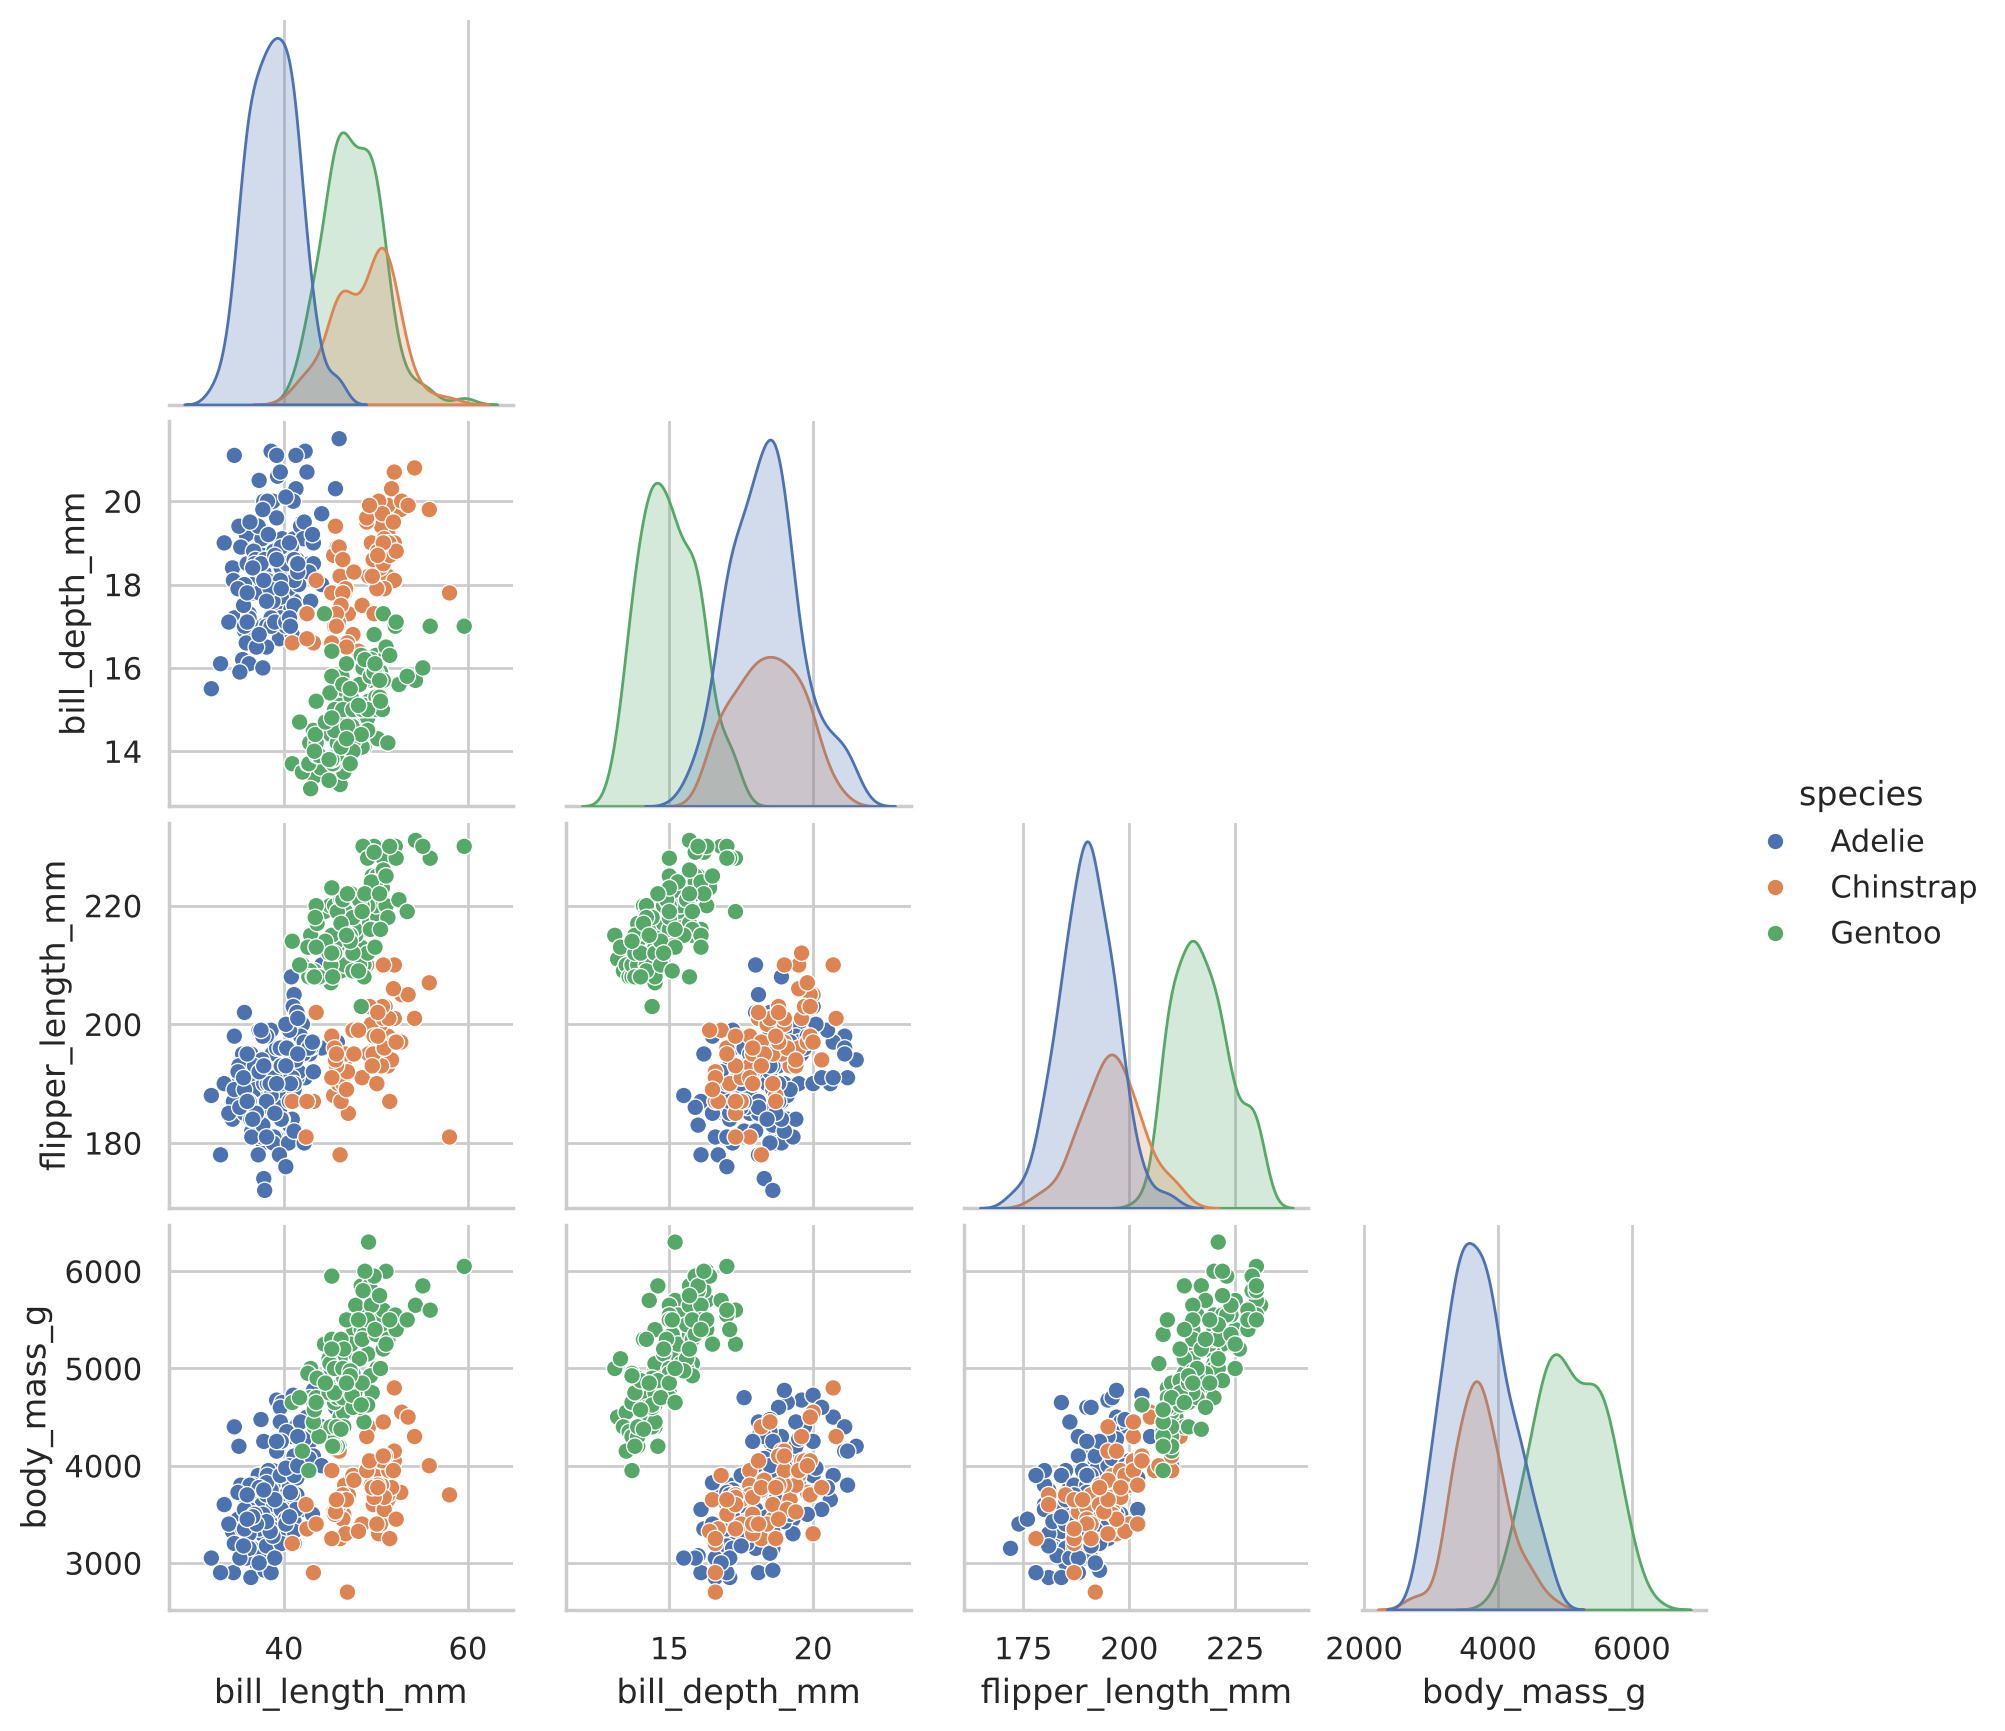

In [9]:
sns.pairplot(penguins, hue="species", corner=True, height=2.2,
             vars=["bill_length_mm", "bill_depth_mm", "flipper_length_mm", "body_mass_g"])
plt.show()

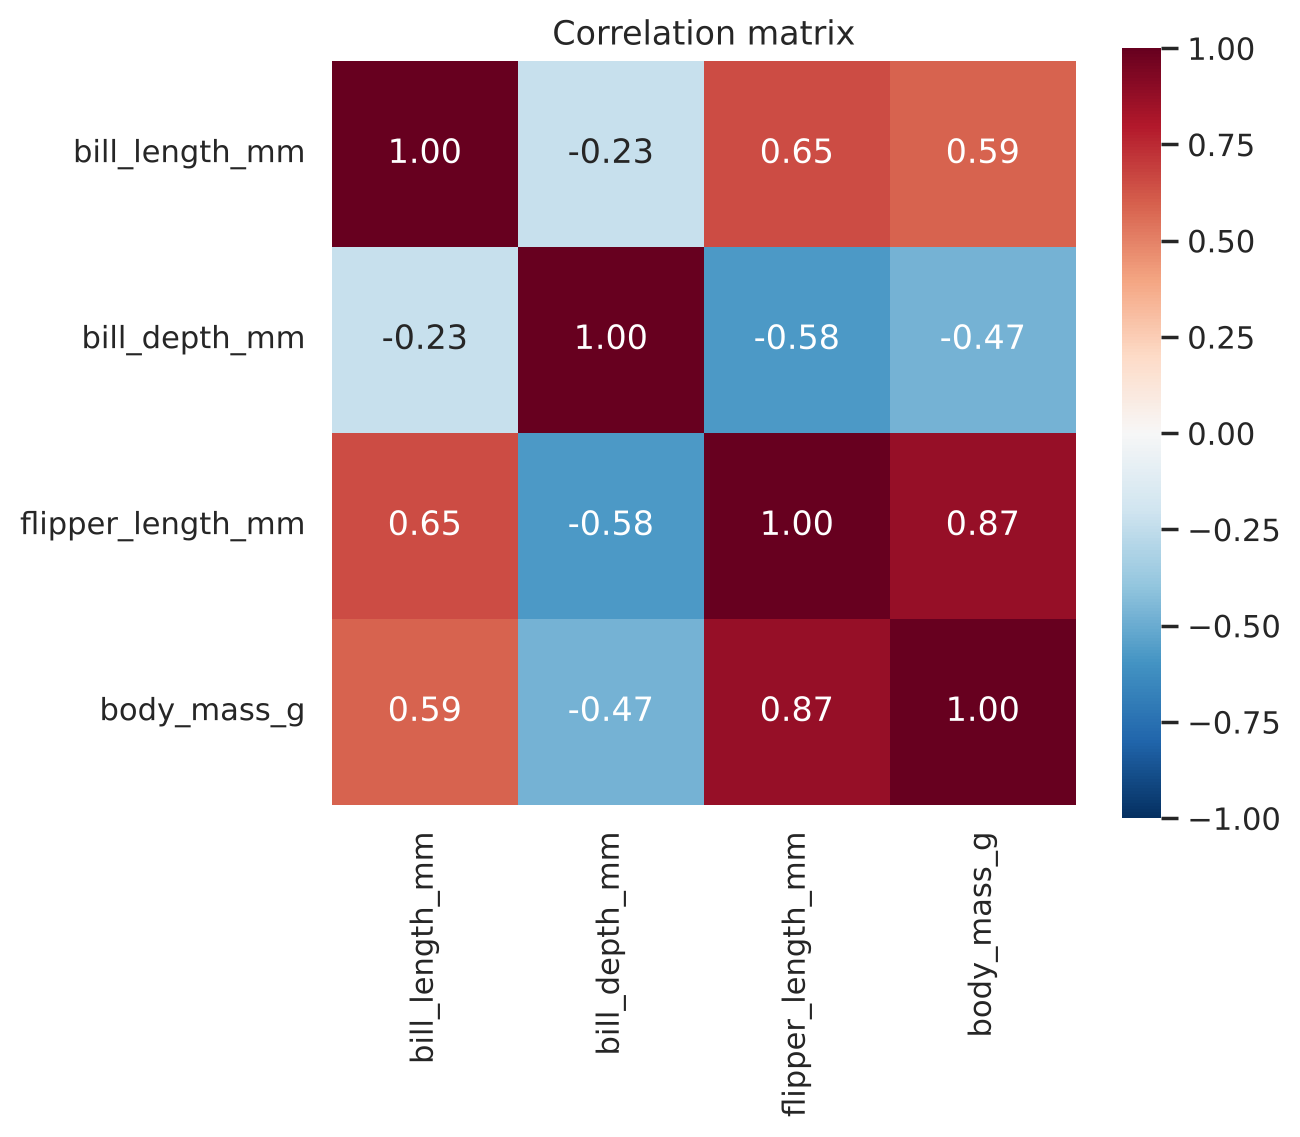

In [10]:
corr = penguins.select_dtypes("number").corr()
fig, ax = plt.subplots(figsize=(6, 5))
sns.heatmap(corr, annot=True, fmt=".2f", cmap="RdBu_r", vmin=-1, vmax=1, center=0, square=True, ax=ax)
ax.set_title("Correlation matrix")
plt.show()

<div dir="rtl">

برای همبستگی که بین ۱- و ۱+ است، از نقشه‌ی رنگ **واگرا (diverging)** با مرکز صفر استفاده کردیم: دو رنگ متضاد برای دو جهت و رنگ خنثی برای صفر.

### نمودارهای چندتایی (Small Multiples)

به‌جای شلوغ کردن یک نمودار با رنگ‌های زیاد، می‌توانیم برای هر گروه یک نمودار کوچک جداگانه با محورهای یکسان رسم کنیم. `relplot`، `displot` و `catplot` با پارامترهای `col` و `row` این کار را انجام می‌دهند.

</div>

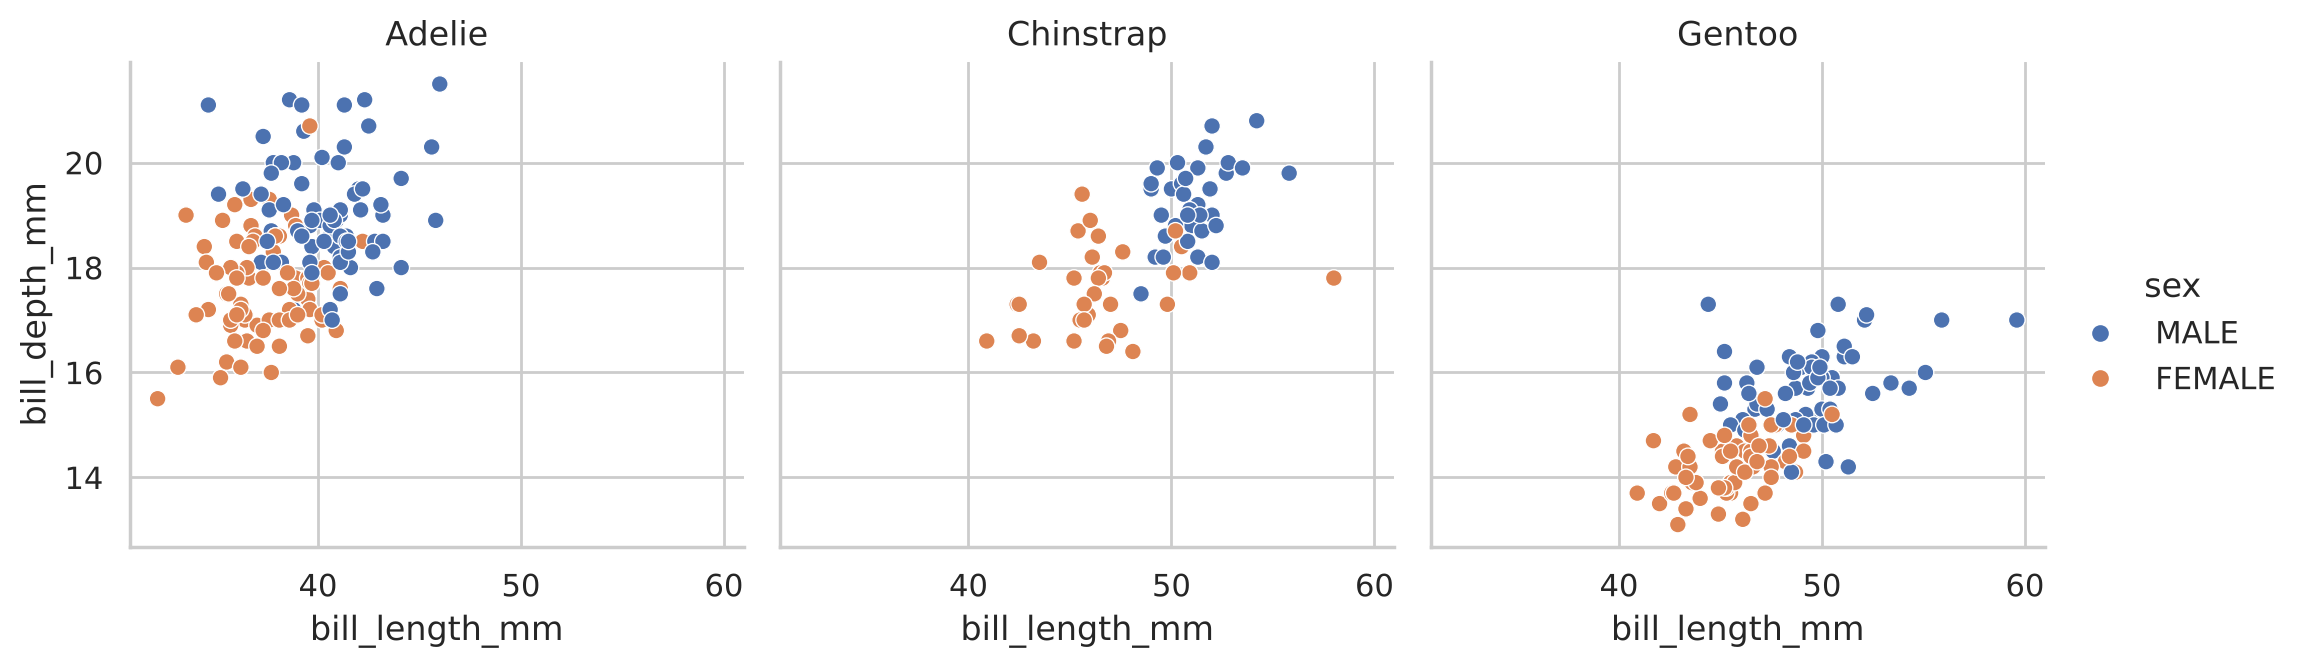

In [11]:
g = sns.relplot(data=penguins, x="bill_length_mm", y="bill_depth_mm",
                col="species", hue="sex", height=3.5)
g.set_titles("{col_name}")
plt.show()

<div dir="rtl">

## ۴. نمودار گمراه‌کننده

نمودار می‌تواند با داده‌ی درست، پیام غلط بدهد. دو نمونه‌ی رایج:

1. **محور عمودی بریده‌شده در نمودار میله‌ای**: طول میله باید متناسب با مقدار باشد؛ اگر محور از صفر شروع نشود، اختلاف‌های کوچک بزرگ دیده می‌شوند.
2. **نقشه‌ی رنگ رنگین‌کمانی** برای مقدار پیوسته: چشم انسان در رنگین‌کمان مرزهای مصنوعی می‌بیند و ترتیب رنگ‌ها را درک نمی‌کند. برای مقدار، از **یک رنگ** با شدت متغیر (روشن به تیره) استفاده کنید.

</div>

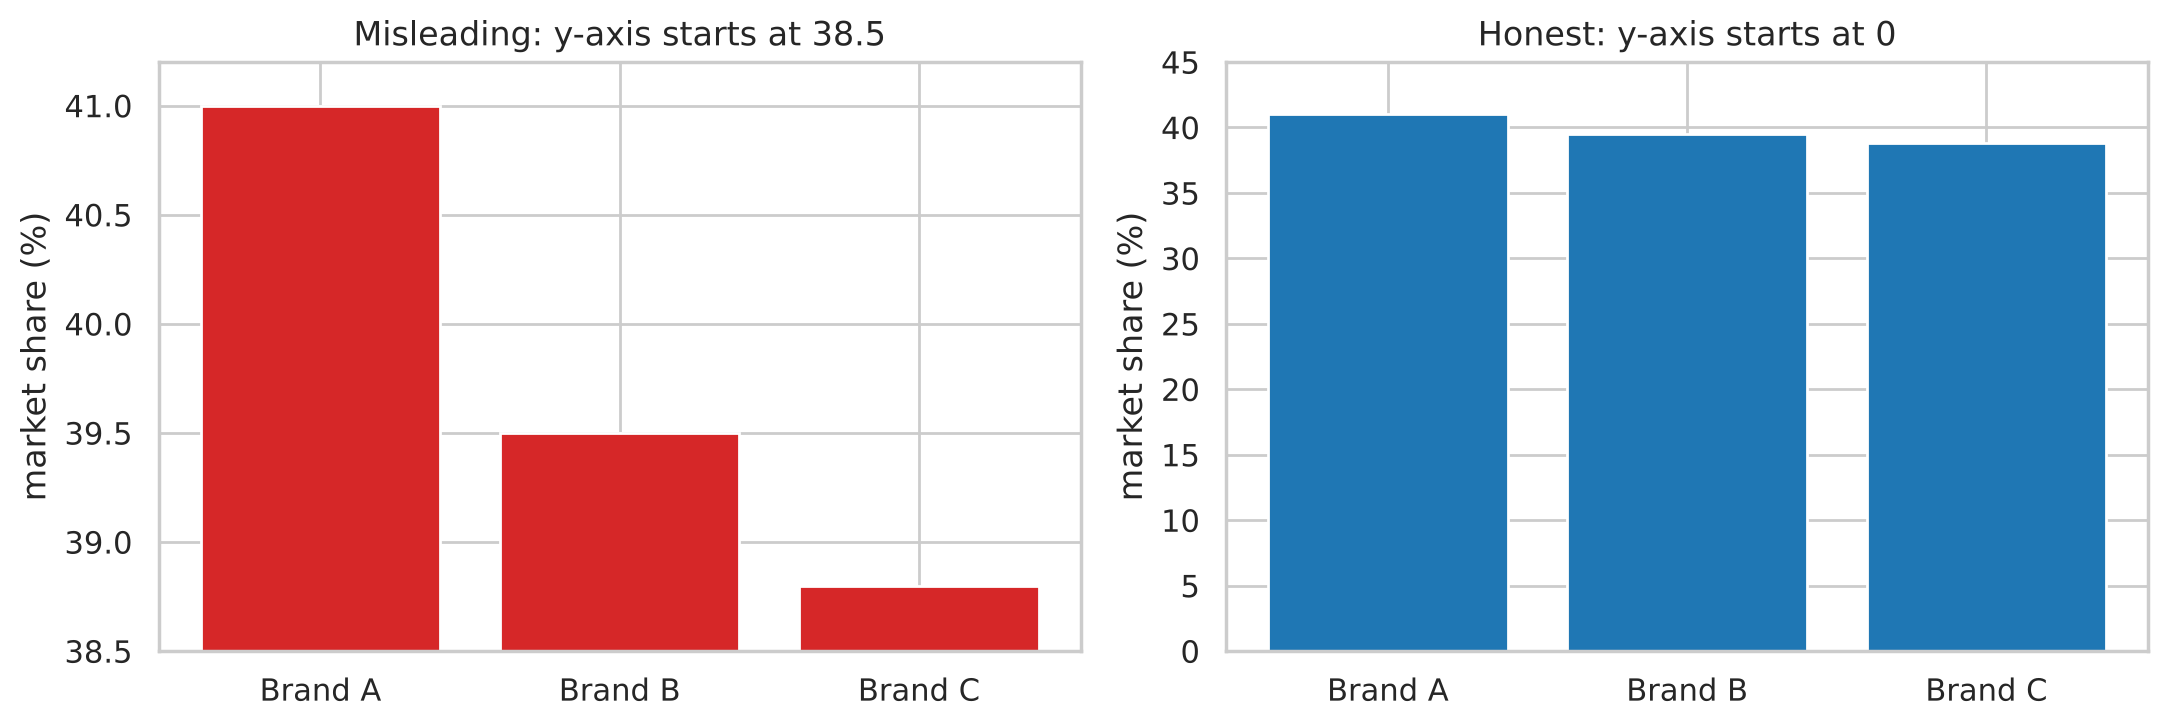

In [12]:
share = pd.Series({"Brand A": 41.0, "Brand B": 39.5, "Brand C": 38.8})

fig, axes = plt.subplots(1, 2, figsize=(11, 3.8))
axes[0].bar(share.index, share.values, color="tab:red")
axes[0].set_ylim(38.5, 41.2)
axes[0].set_title("Misleading: y-axis starts at 38.5")
axes[1].bar(share.index, share.values, color="tab:blue")
axes[1].set_ylim(0, 45)
axes[1].set_title("Honest: y-axis starts at 0")
for ax in axes:
    ax.set_ylabel("market share (%)")
plt.tight_layout()
plt.show()

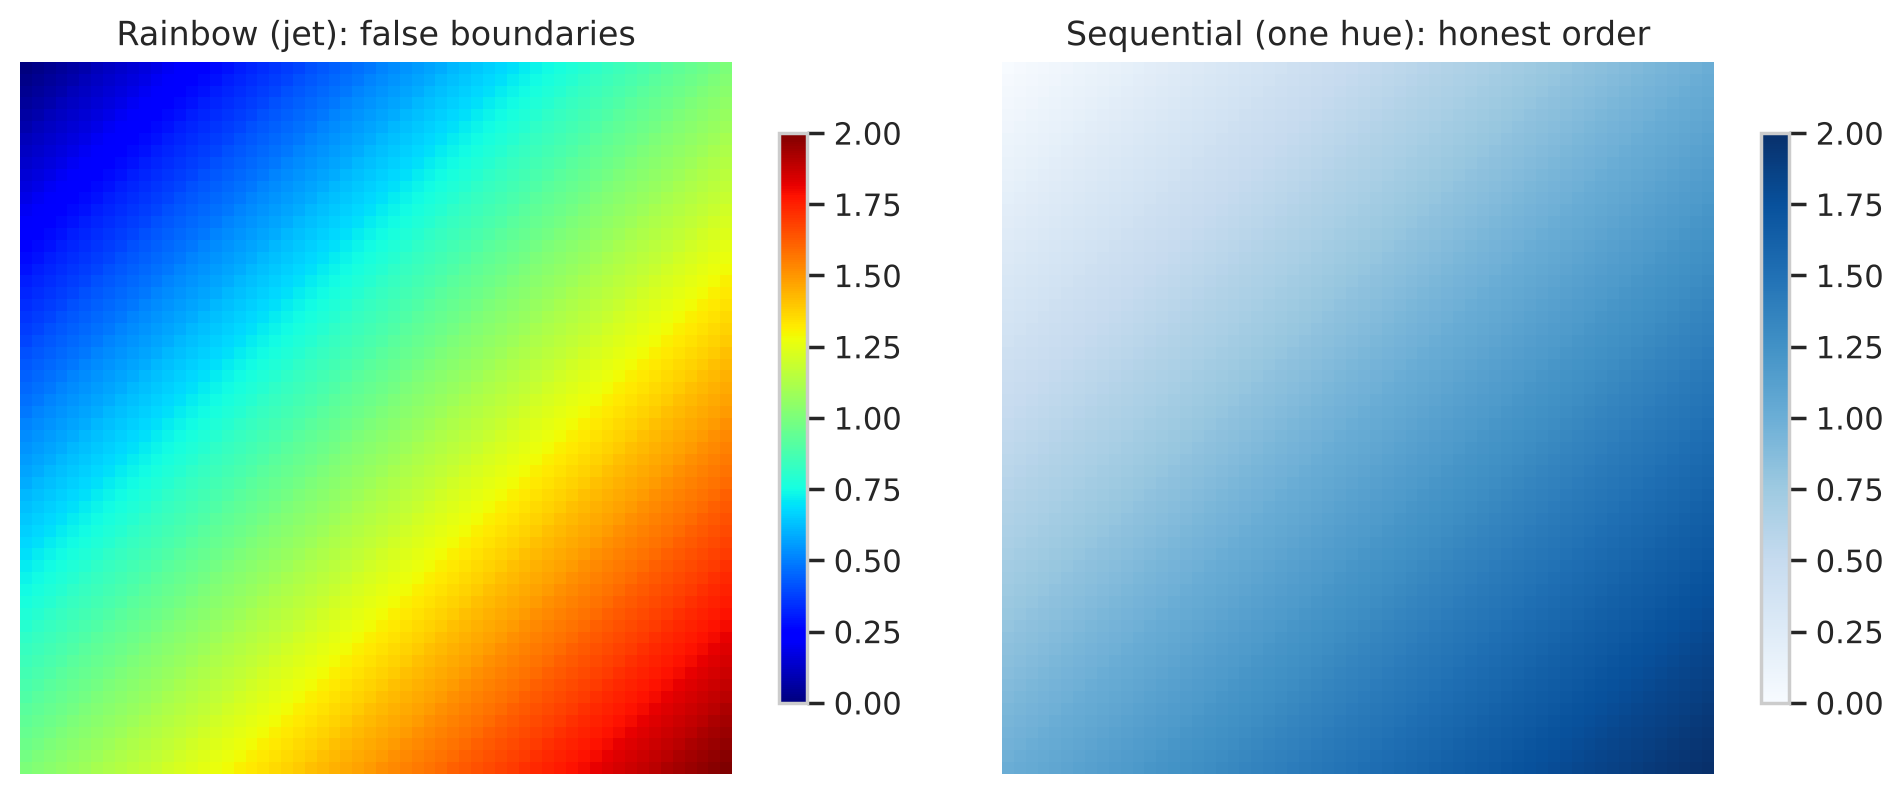

In [13]:
grid = np.add.outer(np.linspace(0, 1, 60), np.linspace(0, 1, 60))
fig, axes = plt.subplots(1, 2, figsize=(10, 4))
for ax, cmap, title in [(axes[0], "jet", "Rainbow (jet): false boundaries"),
                        (axes[1], "Blues", "Sequential (one hue): honest order")]:
    im = ax.imshow(grid, cmap=cmap)
    ax.set_title(title)
    ax.axis("off")
    fig.colorbar(im, ax=ax, shrink=0.8)
plt.tight_layout()
plt.show()

<div dir="rtl">

در تصویر سمت چپ، داده کاملاً پیوسته و یکنواخت است، اما نوارهای زرد و فیروزه‌ای «لبه»‌هایی نشان می‌دهند که در داده وجود ندارد.

### قواعد طلایی

- عنوان نمودار، **پیام** آن را بگوید، نه فقط نام متغیرها.
- محورها برچسب و **واحد** داشته باشند.
- میله‌ها از صفر شروع شوند.
- هرگز دو محور عمودی با مقیاس متفاوت در یک نمودار نگذارید؛ دو نمودار کنار هم بکشید.
- رنگ فقط وقتی که اطلاعات اضافه می‌کند؛ برای دسته‌ها رنگ‌های متمایز، برای مقدار یک رنگ با شدت متغیر، برای مقادیر مثبت/منفی دو رنگ با مرکز خنثی.
- برای تشخیص دسته‌ها فقط به رنگ تکیه نکنید (حدود ۸٪ مردان کوررنگی دارند)؛ از شکل نشانگر یا برچسب مستقیم هم کمک بگیرید.

</div>

<div dir="rtl">

## ۵. یک نمودار کامل برای گزارش

بیایید یک نمودار «تمام‌شده» بسازیم: عنوانی که پیام را می‌گوید، برچسب مستقیم به‌جای راهنمای جداگانه، و حذف عناصر اضافه.

</div>

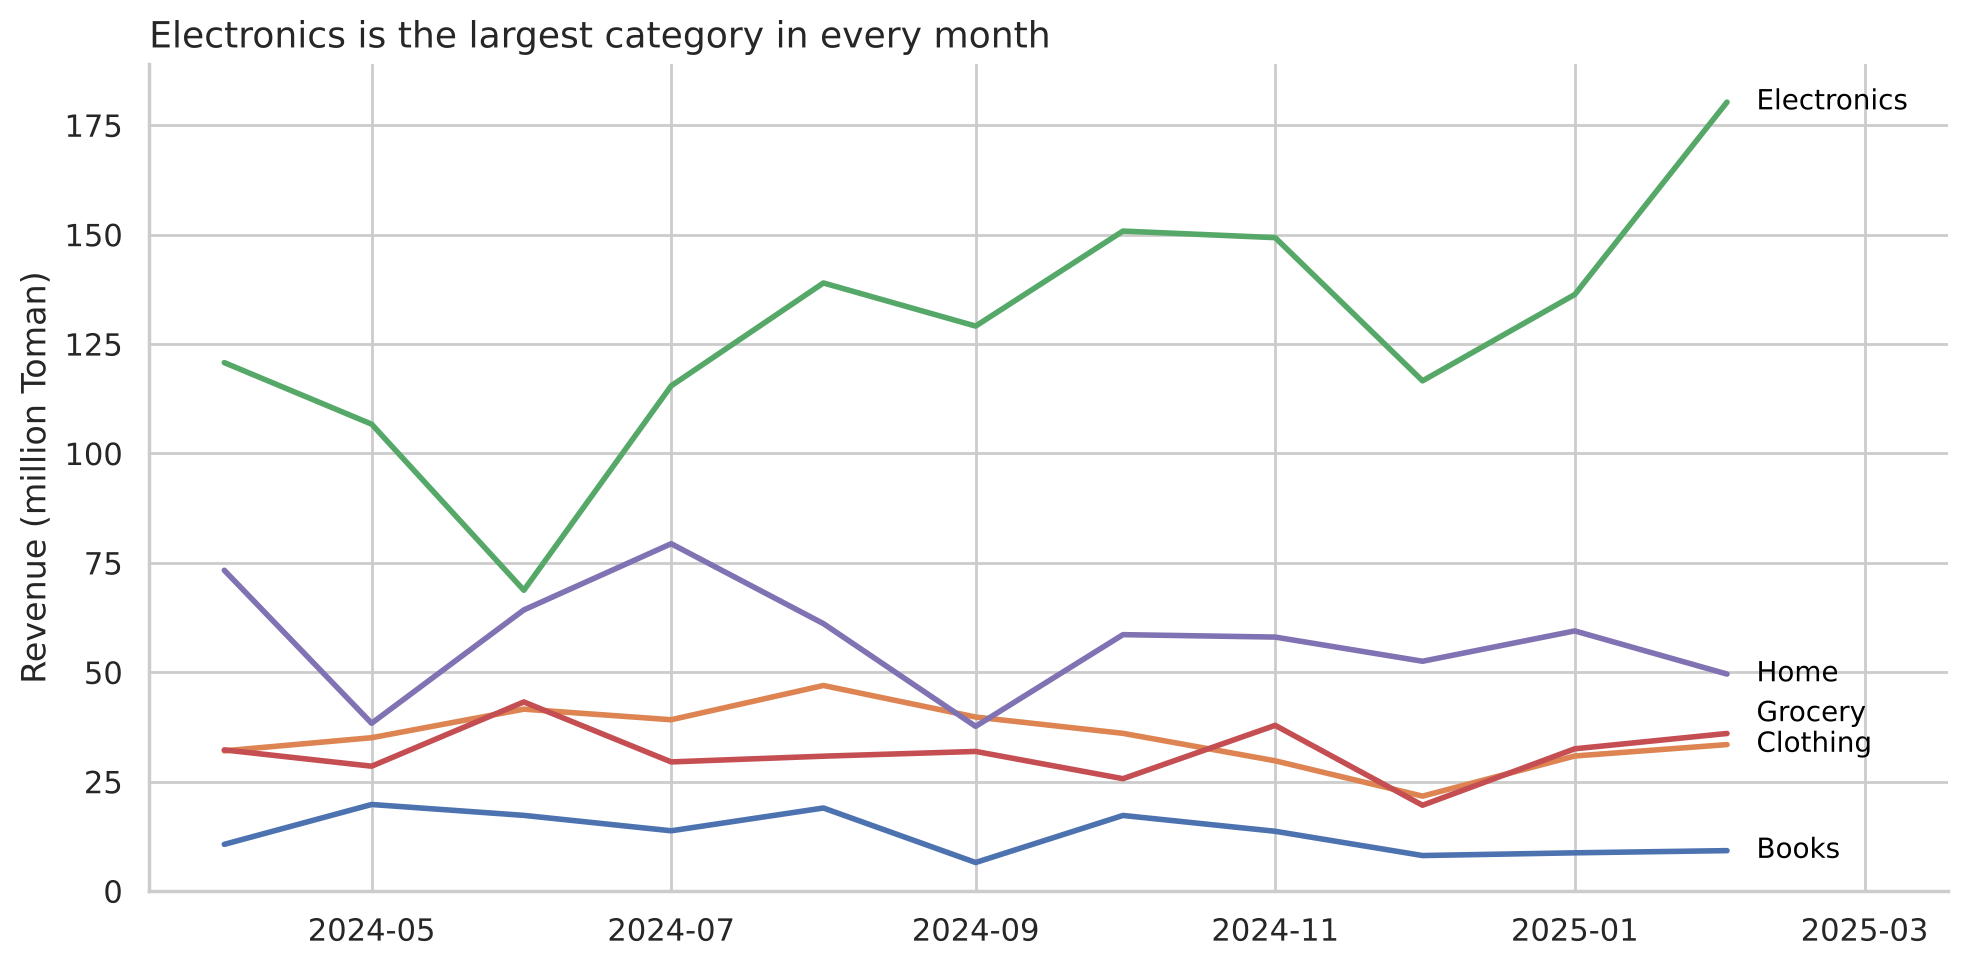

In [14]:
cat_month = (
    orders.merge(pd.read_csv(DATA_URL + "products.csv"), on="product_id")
          .set_index("order_date")
          .groupby("category")
          .resample("MS")["total_price"].sum()
          .div(1e6)
          .unstack(level=0)
          .iloc[1:-1]                     # complete months only
)

# label positions: start at each line's last value, then push apart labels that would overlap
label_y, previous = {}, -np.inf
for name, value in cat_month.iloc[-1].sort_values().items():
    label_y[name] = max(value, previous + 7)
    previous = label_y[name]

fig, ax = plt.subplots(figsize=(10, 5))
for i, col in enumerate(cat_month.columns):
    ax.plot(cat_month.index, cat_month[col], linewidth=2, color=f"C{i}")
    ax.text(cat_month.index[-1] + pd.Timedelta(days=6), label_y[col], col,
            color="black", va="center", fontsize=10)
ax.set_title("Electronics is the largest category in every month", loc="left", fontsize=13)
ax.set_ylabel("Revenue (million Toman)")
ax.spines[["top", "right"]].set_visible(False)
ax.set_xlim(right=cat_month.index[-1] + pd.Timedelta(days=45))
ax.set_ylim(bottom=0)
plt.tight_layout()
fig.savefig("revenue_by_category.png", dpi=200, bbox_inches="tight")
plt.show()

<div dir="rtl">

- `dpi=200` برای چاپ و ارائه کیفیت کافی دارد. برای مقاله، فرمت برداری `pdf` یا `svg` بهتر است چون با بزرگ‌نمایی کیفیتش کم نمی‌شود.
- `bbox_inches="tight"` حاشیه‌ی سفید اضافه را حذف می‌کند.

## جمع‌بندی

- همیشه با `fig, ax = plt.subplots()` شروع کنید و روی `ax` رسم کنید.
- نوع نمودار را **سؤال** تعیین می‌کند: زمان ← خطی، مقایسه ← میله‌ای، توزیع ← هیستوگرام/جعبه‌ای، رابطه ← پراکندگی.
- Seaborn با `hue`، `col` و `row` مقایسه‌ی گروه‌ها را ساده می‌کند.
- نمودار صادق: محور از صفر برای میله، رنگ مناسب نوع داده، یک محور عمودی، عنوانِ پیام‌دار.

## تمرین

1. توزیع `total_bill` در داده‌ی `tips` را با هیستوگرام رسم کنید. توزیع متقارن است یا چوله؟ نمودار `np.log` آن را هم رسم کنید.
2. با `sns.boxplot`، مدت ارسال سفارش‌ها (`delivery_days`) را بین شهرها مقایسه کنید. شهرها را بر اساس میانه مرتب کنید.
3. رابطه‌ی `total_bill` و `tip` را با `sns.regplot` رسم کنید. آیا رابطه برای ناهار و شام فرق دارد؟ (راهنما: `sns.lmplot` با `col="time"`)
4. نمودار میله‌ای تعداد سفارش در هر ساعت از روز را رسم کنید و عنوانی بنویسید که پیام اصلی آن را بگوید.
5. یک نمودار گمراه‌کننده از داده‌ی فروشگاه بسازید و کنارش نسخه‌ی صادق آن را رسم کنید. در یک جمله توضیح دهید چرا اولی گمراه‌کننده است.

</div>